In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelBinarizer, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)


In [3]:
from cclf import ConsensusClassifier

In [4]:
# 1. Generate synthetic multi-class data
n_classes = 7
X, y = make_classification(
    n_samples=400,
    n_features=2000,
    n_informative=500,
    n_redundant=200,
    n_repeated=100,
    n_classes=n_classes,
    weights=[0.4, 0.2, 0.15, 0.1, 0.07, 0.05, 0.03],
    class_sep=2.0,
    random_state=42
)
X = pd.DataFrame(X)
y = pd.Series(y)

In [5]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
y_multi = y_train.copy()
y_train = (y_multi == 6).astype(int)
y_test = (y_test == 6).astype(int)

In [15]:
# 2. Define and train the logistic regression model
model = ConsensusClassifier(
    n_models=100, 
    n_samples_per_model=10, 
    n_features_per_model=200, 
    keep_samples=y_multi[y_multi == 6].index.tolist(), 
    # keep_features=X_train.columns.tolist()[:10]
    )
model.add_train_data(X_train, y_train, y_multi=y_multi)
model.add_test_data(X_test)
_ = model.fit(seed=42)

# Make predictions
y_pred = model.predict()
probs = model.predict_proba()

2025-01-23 09:46:25,584 - cclf.clf - INFO - ========== Initializing Consensus Classifier ==========
2025-01-23 09:46:25,586 - cclf.clf - INFO - Finished! Call the `add_train_data` method to load the training data.
2025-01-23 09:46:25,588 - cclf.clf - INFO - Checking training data...


2025-01-23 09:46:25,600 - cclf.clf - INFO - Loaded training data with 280 samples and 2000 features.
2025-01-23 09:46:25,601 - cclf.clf - INFO - Found 2 classes in the training data.
2025-01-23 09:46:25,601 - cclf.clf - INFO - Each model will be trained on 10 samples.
2025-01-23 09:46:25,602 - cclf.clf - INFO - Finished! Call the `add_test_data` method to load the test data.
2025-01-23 09:46:25,603 - cclf.clf - INFO - Checking training data...
2025-01-23 09:46:25,608 - cclf.clf - INFO - Loaded test data with 120 samples and 2000 features.
2025-01-23 09:46:25,611 - cclf.clf - INFO - Subsetting features of the test data...
2025-01-23 09:46:25,619 - cclf.clf - INFO - Each model will be trained on 200 features.
2025-01-23 09:46:25,619 - cclf.clf - INFO - Finished! Call the `fit` method to train the classifiers.
2025-01-23 09:46:25,620 - cclf.clf - INFO - Training the classifiers...


100%|██████████| 100/100 [00:23<00:00,  4.23it/s]

2025-01-23 09:46:49,240 - cclf.clf - INFO - Finished! Call the `predict` method to classify the test data.


In [16]:
# # 2. Define and train the logistic regression model
# model = LogisticRegression(multi_class='ovr', solver='lbfgs', max_iter=1000, random_state=42)
# model.fit(X_train, y_train)
# # Make predictions
# y_pred = model.predict(X_test)
# probs = model.predict_proba(X_test)

<Axes: >

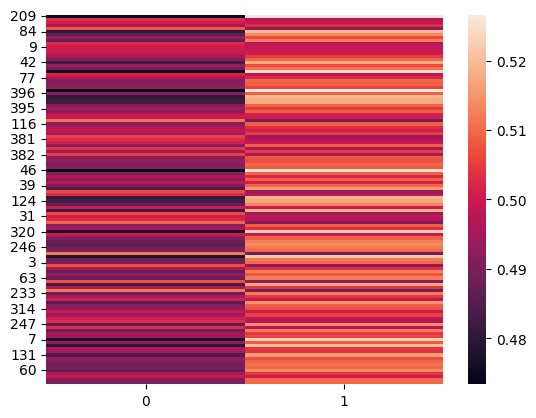

In [17]:
sns.heatmap(probs)

In [18]:
# One-hot encode the labels for AUROC calculation
ohe = LabelBinarizer()
y_train_ohe = ohe.fit_transform(y_train)
y_test_ohe = ohe.transform(y_test)

if len(y_train.unique()) == 2:
    y_train_ohe = y_train
    y_test_ohe = y_test

In [19]:
# 3. Compute metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")


Accuracy: 0.2667
Precision: 0.9528
Recall: 0.2667
F1 Score: 0.4068


In [20]:
probs[1]

209    0.525602
280    0.497000
33     0.499575
210    0.503704
93     0.491940
         ...   
60     0.513534
79     0.504206
285    0.500341
305    0.509527
281    0.509931
Name: 1, Length: 120, dtype: float32

In [21]:
# AUROC
auroc = roc_auc_score(y_test_ohe, probs[1], average="weighted", multi_class="ovr")
print(f"Weighted AUROC: {auroc:.4f}")


Weighted AUROC: 0.2246


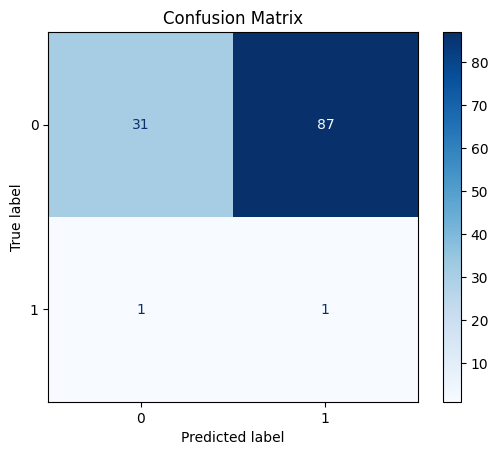

In [22]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=ohe.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()


KeyError: 'key of type tuple not found and not a MultiIndex'

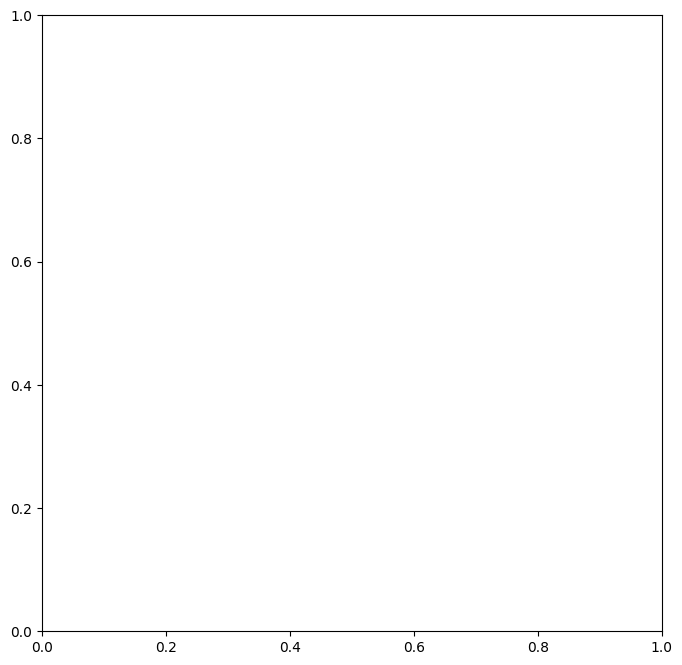

In [23]:
from sklearn.metrics import  RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 8))


for class_id in range(n_classes):
    RocCurveDisplay.from_predictions(
        y_test_ohe[:, class_id],
        probs.loc[:, class_id],
        name=f"{class_id} vs Rest",
        # color=c,
        linewidth=4,
        ax=ax,
        # alpha={True: 1.0, False: 0.5}[class_id == 3],
    )

ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate")

In [ ]:
set(X_train.index[:10]) == set(X_train.index[:10]) & set(model.sample_subset_list[1])